**Question 1**

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
import numpy as np

PATH = "diagnosis.data"
FEATURE_COLS = ["temp", "nausea", "lumbar_pain", "urine_pushing", "micturition_pain", "urethra_burning"]
LABEL_COLS = ["bladder", "nephritis"]

In [3]:
df = pd.read_csv(PATH, sep="\t", decimal=",", header=None, encoding = "utf-16", names=FEATURE_COLS + LABEL_COLS)
yes_no_cols = FEATURE_COLS[1:] + LABEL_COLS
df[yes_no_cols] = df[yes_no_cols].eq("yes").astype(int)
df.head()

,temp,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [5]:
X = df[FEATURE_COLS]
y_powerset = df["bladder"].astype(str) + "_" + df["nephritis"].astype(str)
y_powerset.value_counts()

1_0    40
0_1    31
0_0    30
1_1    19
Name: count, dtype: int64

depth: 4 , leaves: 6 , train accuracy: 1.0


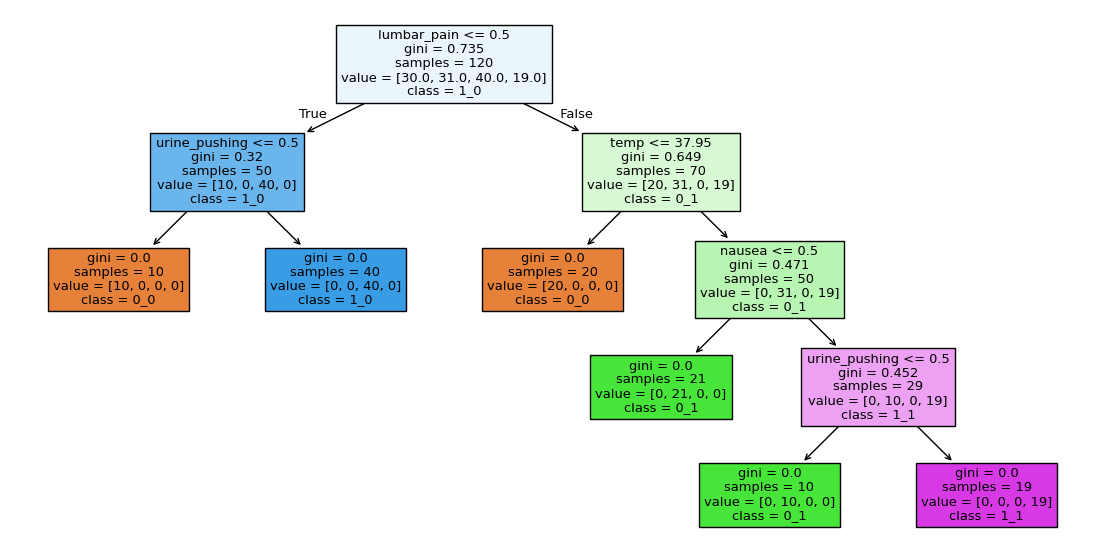

In [12]:
tree = DecisionTreeClassifier(random_state=42).fit(X, y_powerset)
print("depth:", tree.get_depth(), ", leaves:", tree.get_n_leaves(),", train accuracy:", tree.score(X, y_powerset))

plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=FEATURE_COLS, class_names=tree.classes_, filled=True)
plt.show()

In [17]:
def tree_rules(tree, feature_names):
    t = tree.tree_
    rules = []
    def recurse(node, conditions):
        if t.children_left[node] == -1:
            label = tree.classes_[t.value[node].argmax()]
            rules.append(f"IF {' AND '.join(conditions)} THEN {label}  (n={t.n_node_samples[node]})")
            return
        name, threshold = feature_names[t.feature[node]], t.threshold[node]
        recurse(t.children_left[node], conditions + [f"{name} <= {threshold:.2f}"])
        recurse(t.children_right[node], conditions + [f"{name} > {threshold:.2f}"])

    recurse(0, [])
    return rules

full_rules = tree_rules(tree, FEATURE_COLS)
for rule in full_rules:
    print(rule)


IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN 0_0  (n=10)
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN 1_0  (n=40)
IF lumbar_pain > 0.50 AND temp <= 37.95 THEN 0_0  (n=20)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea <= 0.50 THEN 0_1  (n=21)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN 0_1  (n=10)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN 1_1  (n=19)


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_folds = 5
cv_splitter = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)

pruning_path = tree.cost_complexity_pruning_path(X, y_powerset)
pruning_path.ccp_alphas

array([0.        , 0.09816667, 0.13333333, 0.182     , 0.22291667])

In [19]:
pruning_results = []
for alpha in pruning_path.ccp_alphas:
    pruned_tree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha).fit(X, y_powerset)
    cv_accuracy = cross_val_score(DecisionTreeClassifier(random_state=42, ccp_alpha=alpha),
                                  X, y_powerset, cv=cv_splitter).mean()
    pruning_results.append({"alpha": alpha, "leaves": pruned_tree.get_n_leaves(),
                            "train_acc": pruned_tree.score(X, y_powerset), "cv_acc": cv_accuracy})
pruning_df = pd.DataFrame(pruning_results).round(3)
pruning_df

,alpha,leaves,train_acc,cv_acc
0,0.000,6,1.000,0.992
1,0.098,4,0.842,0.858
2,0.133,3,0.758,0.758
3,0.182,2,0.592,0.667
4,0.223,1,0.333,0.483


In [22]:
ACCURACY_TOLERANCE = 0.01
best_cv_acc = pruning_df["cv_acc"].max()
chosen_alpha = pruning_df.loc[pruning_df["cv_acc"] >= best_cv_acc - ACCURACY_TOLERANCE, "alpha"].max()

minimal_tree = DecisionTreeClassifier(random_state=42, ccp_alpha=chosen_alpha).fit(X, y_powerset)
print("chosen alpha:", chosen_alpha, "| leaves:", minimal_tree.get_n_leaves())
for rule in tree_rules(minimal_tree, FEATURE_COLS):
    print(rule)


chosen alpha: 0.0 | leaves: 6
IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN 0_0  (n=10)
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN 1_0  (n=40)
IF lumbar_pain > 0.50 AND temp <= 37.95 THEN 0_0  (n=20)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea <= 0.50 THEN 0_1  (n=21)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN 0_1  (n=10)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN 1_1  (n=19)


**Question 1d.**

- Performing cost complexity pruning path yielded a : {0, 0.098, 0.133, 0.182, 0.223}. Using a 5 fold stratified cv, a = 0 gave 99.2% CV accruacy, with the next a(4 leaves) dropping to 85.8% since pruning the nausea split removes the ability to predict the both diseases class. By selecting the largest a within 1 point of the best CV accuracy gives a=0; therefore, the unpruned 6 leaf tree is already the minimal tree. 

The Decision Rules:
1. No lumbar pain, no urine pushing -> healthy
2. No lumbar pain, urine pushing -> bladder inflammation only
3. Lumbar pain, temp <=> 37.95 °C -> healthy
4. Lumbar pain, temp > 37.95 °C, no nausea -> nephritis only
5. Lumbar pain, temp > 37.95 °C, nausea, no urine pushing -> nephritis only
6. Lumbar pain, temp > 37.95 °C, nausea, urine pushing -> both

**Question 2**

In [ ]:
import pandas as pd
from sklearn.impute import SimpleImputer

DATA_PATH = "communities.data"
NAMES_PATH = "communities.names"
TRAIN_ROWS = 1495
TARGET_COL = "ViolentCrimesPerPop"
NON_PREDICTIVE_COLS = ["state", "county", "community", "communityname", "fold"]

In [25]:
column_names = [line.split()[1] for line in open(NAMES_PATH) if line.startswith("@attribute")]
crime_df = pd.read_csv(DATA_PATH, header=None, names=column_names, na_values="?")
crime_df = crime_df.drop(columns=NON_PREDICTIVE_COLS)
crime_df.shape

(1994, 123)

In [26]:
train_df, test_df = crime_df.iloc[:TRAIN_ROWS], crime_df.iloc[TRAIN_ROWS:]
X_train, y_train = train_df.drop(columns=TARGET_COL), train_df[TARGET_COL]
X_test,  y_test  = test_df.drop(columns=TARGET_COL),  test_df[TARGET_COL]

missing_counts = X_train.isna().sum()
missing_counts[missing_counts > 0].sort_values()

OtherPerCap                1
LemasSwornFT            1256
LemasSwFTPerPop         1256
LemasSwFTFieldOps       1256
LemasSwFTFieldPerPop    1256
LemasTotalReq           1256
LemasTotReqPerPop       1256
PolicReqPerOffic        1256
PolicPerPop             1256
RacialMatchCommPol      1256
PctPolicWhite           1256
PctPolicBlack           1256
PctPolicHisp            1256
PctPolicAsian           1256
PctPolicMinor           1256
OfficAssgnDrugUnits     1256
NumKindsDrugsSeiz       1256
PolicAveOTWorked        1256
PolicCars               1256
PolicOperBudg           1256
LemasPctPolicOnPatr     1256
LemasGangUnitDeploy     1256
PolicBudgPerPop         1256
dtype: int64

In [28]:
imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)
print("NaNs left:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

NaNs left: 0 0


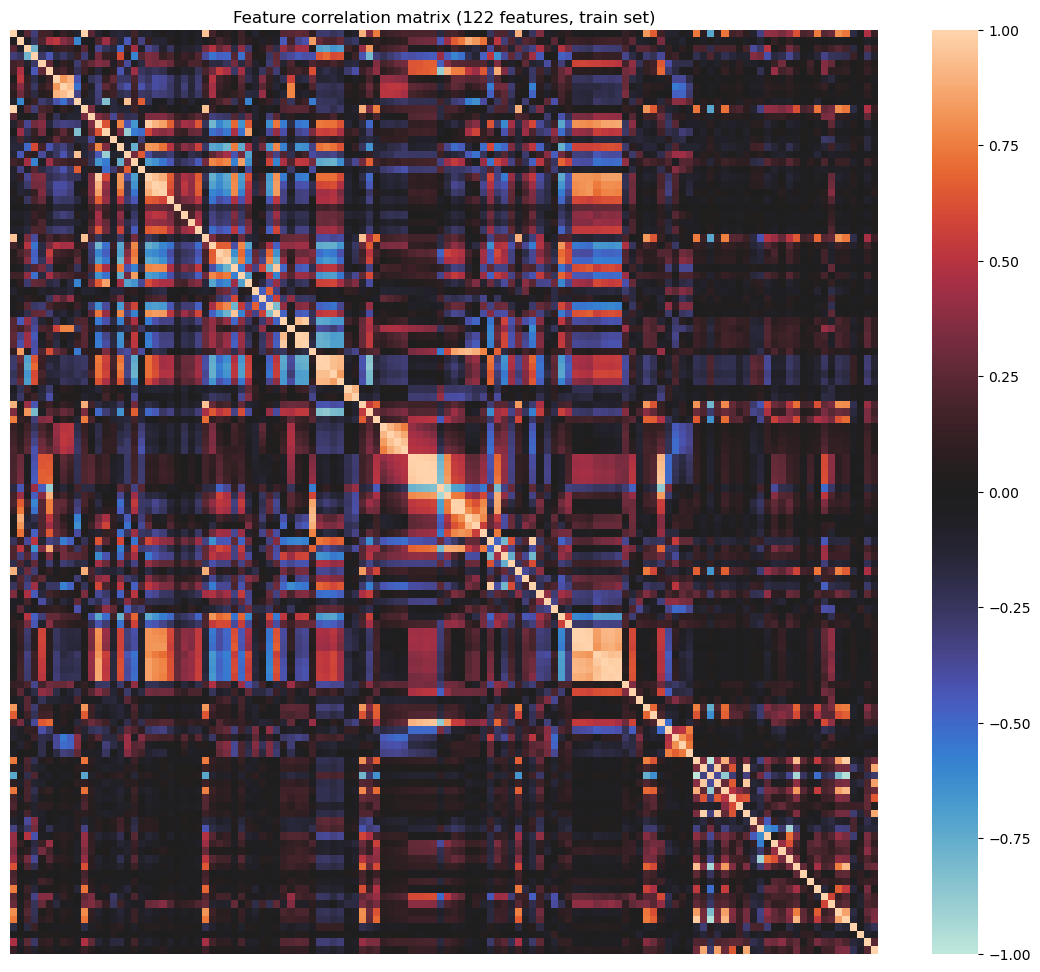

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

feature_corr = X_train.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(feature_corr, vmin=-1, vmax=1, center=0,
            xticklabels=False, yticklabels=False)
plt.title("Feature correlation matrix (122 features, train set)")
plt.show()

**Question 2d**

In [35]:
feature_cv = (X_train.std() / X_train.mean()).sort_values(ascending=False)
feature_cv.round(3)

PctPolicAsian          5.527
NumStreet              4.293
NumInShelters          3.471
NumIlleg               3.059
NumImmig               2.927
                       ...  
NumKindsDrugsSeiz      0.141
RacialMatchCommPol     0.130
PctPolicWhite          0.119
LemasPctPolicOnPatr    0.112
LemasSwFTFieldOps      0.064
Length: 122, dtype: float64

**Question 2e**

In [36]:
TOP_K_FEATURES = int(np.floor(np.sqrt(128)))
top_cv_features = feature_cv.head(TOP_K_FEATURES).index.tolist()
top_cv_features

['PctPolicAsian',
 'NumStreet',
 'NumInShelters',
 'NumIlleg',
 'NumImmig',
 'LemasPctOfficDrugUn',
 'NumUnderPov',
 'LemasSwornFT',
 'population',
 'numbUrban',
 'HousVacant']

**Question 2f**

In [39]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

ols_model = LinearRegression().fit(X_train, y_train)

ols_train_mse = mean_squared_error(y_train, ols_model.predict(X_train))
ols_test_mse  = mean_squared_error(y_test,  ols_model.predict(X_test))
baseline_test_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))

print(f"OLS train MSE: {ols_train_mse:.4f}")
print(f"OLS test MSE:  {ols_test_mse:.4f}")
print(f"Baseline (predict train mean) test MSE: {baseline_test_mse:.4f}")

ols_coefs = pd.Series(ols_model.coef_, index=X_train.columns)
print(ols_coefs[["LemasSwFTPerPop", "PolicPerPop"]])
ols_coefs.abs().sort_values(ascending=False).head(10)

OLS train MSE: 0.0163
OLS test MSE:  0.0180
Baseline (predict train mean) test MSE: 0.0477
LemasSwFTPerPop   -0.013836
PolicPerPop       -0.013836
dtype: float64


PctPersOwnOccup         0.892380
PctHousOwnOcc           0.773396
TotalPctDiv             0.682847
PolicOperBudg           0.548009
MalePctDivorce          0.526901
OwnOccMedVal            0.478263
PersPerOccupHous        0.466204
OwnOccLowQuart          0.398064
LemasSwFTFieldPerPop    0.395529
MedRent                 0.374523
dtype: float64

**Question 2g**

In [43]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold

LAMBDA_GRID = np.logspace(-3, 3, 100)
reg_cv_splitter = KFold(n_splits=10, shuffle=True, random_state=42)

ridge_model = RidgeCV(alphas=LAMBDA_GRID, cv=reg_cv_splitter,
                      scoring="neg_mean_squared_error").fit(X_train, y_train)
ridge_test_mse = mean_squared_error(y_test, ridge_model.predict(X_test))

print(f"chosen lambda: {ridge_model.alpha_:.3f}")
print(f"CV MSE: {-ridge_model.best_score_:.4f}")
print(f"Ridge test MSE: {ridge_test_mse:.4f}  (OLS was {ols_test_mse:.4f})")

chosen lambda: 3.275
CV MSE: 0.0192
Ridge test MSE: 0.0175  (OLS was 0.0180)


In [44]:
ridge_coefs = pd.Series(ridge_model.coef_, index=X_train.columns)
pd.DataFrame({"ols": ols_coefs, "ridge": ridge_coefs}).loc[
    ["PctPersOwnOccup", "PctHousOwnOcc", "TotalPctDiv", "MalePctDivorce"]].round(3)

,ols,ridge
PctPersOwnOccup,-0.892,-0.054
PctHousOwnOcc,0.773,0.007
TotalPctDiv,-0.683,-0.002
MalePctDivorce,0.527,0.100


Ridge(λ = 3.275) using 10 fold CV, with CV MSE = 0.0192. Test MSE = 0.0175 vs OLS = 0.0180. 

The gain is small since OLS seemed to be only slightly overfit but ridge stabilized coefficients. 

**Question 2h**

In [45]:
from sklearn.linear_model import LassoCV

LASSO_MAX_ITER = 50000

lasso_model = LassoCV(cv=reg_cv_splitter, random_state=42,
                      max_iter=LASSO_MAX_ITER).fit(X_train, y_train)
lasso_test_mse = mean_squared_error(y_test, lasso_model.predict(X_test))
lasso_coefs = pd.Series(lasso_model.coef_, index=X_train.columns)
lasso_selected = lasso_coefs[lasso_coefs != 0].sort_values()

print(f"chosen lambda: {lasso_model.alpha_:.6f}")
print(f"LASSO test MSE: {lasso_test_mse:.4f}")
print(f"features selected: {len(lasso_selected)} of {X_train.shape[1]}")
lasso_selected.round(3)

chosen lambda: 0.000125
LASSO test MSE: 0.0176
features selected: 74 of 122


agePct12t29        -0.249
PctKids2Par        -0.198
RentLowQ           -0.154
PctPopUnderPov     -0.138
PctWorkMom         -0.127
                    ...  
PctEmploy           0.130
MedRent             0.154
NumStreet           0.157
PctPersDenseHous    0.209
racepctblack        0.267
Length: 74, dtype: float64

In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lasso_std_model = make_pipeline(
    StandardScaler(),
    LassoCV(cv=reg_cv_splitter, random_state=42, max_iter=LASSO_MAX_ITER),
).fit(X_train, y_train)
lasso_std_test_mse = mean_squared_error(y_test, lasso_std_model.predict(X_test))
lasso_std_coefs = pd.Series(lasso_std_model[-1].coef_, index=X_train.columns)
lasso_std_selected = lasso_std_coefs[lasso_std_coefs != 0].sort_values()

print(f"chosen lambda: {lasso_std_model[-1].alpha_:.6f}")
print(f"LASSO (standardized) test MSE: {lasso_std_test_mse:.4f}")
print(f"features selected: {len(lasso_std_selected)} of {X_train.shape[1]}")
print("selected by both:", len(set(lasso_selected.index) & set(lasso_std_selected.index)))

chosen lambda: 0.000664
LASSO (standardized) test MSE: 0.0177
features selected: 75 of 122
selected by both: 73


LASSO selected 74 of 122 features with test MSE of 0.0176. With standardized features, it selected 75 with a test MSE of 0.0177 with 73 feature sin common. It seems like standardization doesnt really matter since features are already normalized.

**Question 2i**

In [47]:
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV

COMPONENT_GRID = range(1, X_train.shape[1] + 1)

pcr_pipeline = make_pipeline(PCA(), LinearRegression())
pcr_search = GridSearchCV(pcr_pipeline, {"pca__n_components": COMPONENT_GRID},
                          cv=reg_cv_splitter, scoring="neg_mean_squared_error").fit(X_train, y_train)

pcr_test_mse = mean_squared_error(y_test, pcr_search.predict(X_test))
print(f"chosen M: {pcr_search.best_params_['pca__n_components']}")
print(f"CV MSE: {-pcr_search.best_score_:.4f}")
print(f"PCR test MSE: {pcr_test_mse:.4f}")

chosen M: 65
CV MSE: 0.0196
PCR test MSE: 0.0184


The chosen M = 65 with PCT Test MSE at 0.0184

**Question 2j**

In [48]:
from xgboost import XGBRegressor

XGB_ALPHA_GRID = np.logspace(-4, 1, 11)
XGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, max_depth=3,
                  random_state=42, n_jobs=-1)

xgb_search = GridSearchCV(XGBRegressor(**XGB_PARAMS), {"reg_alpha": XGB_ALPHA_GRID},
                          cv=reg_cv_splitter, scoring="neg_mean_squared_error").fit(X_train, y_train)

In [51]:
xgb_model = xgb_search.best_estimator_
xgb_train_mse = mean_squared_error(y_train, xgb_model.predict(X_train))
xgb_test_mse  = mean_squared_error(y_test,  xgb_model.predict(X_test))

print(f"chosen alpha: {xgb_search.best_params_['reg_alpha']:.4f}")
print(f"CV MSE: {-xgb_search.best_score_:.4f}")
print(f"XGB train MSE: {xgb_train_mse:.4f}")
print(f"XGB test MSE:  {xgb_test_mse:.4f}")
pd.Series(-xgb_search.cv_results_["mean_test_score"], index=XGB_ALPHA_GRID.round(4)).round(5)

chosen alpha: 0.3162
CV MSE: 0.0198
XGB train MSE: 0.0063
XGB test MSE:  0.0163


0.0001     0.02017
0.0003     0.02015
0.0010     0.02010
0.0032     0.02007
0.0100     0.01999
0.0316     0.02011
0.1000     0.02001
0.3162     0.01985
1.0000     0.01996
3.1623     0.02004
10.0000    0.02155
dtype: float64

The chosen alpha is .3162